Main model. Features available at chapter 3: S = tags, content warnings, original or fan fiction, length of chapters 1–3 and days between them (75 columns); A = first book or not, number of earlier books (2); T = the first three chapters embedded with `text-embedding-3-small` and pooled into one 1,536-d vector. Every model is tuned on 2022 and scored once on 2023.

Recall@slots: each quarter gets as many slots as it has future hits; the share of those slots that go to a future hit (random = 0.10). Source: `modeling/01_ml.py`, `02_dl.py`, `03_compare.py` → `modeling/out/results.json`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
load = lambda rel: json.loads((ROOT / rel).read_text())
show = lambda rel, width=720: display(Image(filename=str(ROOT / rel), width=width))
pd.set_option("display.precision", 3)

In [2]:
r = load("modeling/out/results.json")
LABEL = {"rule_fast_update": "Rule: fastest updates first", "rule_known_author": "Rule: experienced authors first",
         "rule_hot_genre": "Rule: popular genres first", "lr_S": "LR: tags + structure (S)", "lr_SA": "LR: + author (S+A)",
         "lr_SAT": "LR: + chapter text (S+A+T), main", "gb_SAT": "Gradient boosting: S+A+T", "mlp_SAT": "MLP: S+A+T",
         "lr_T": "LR: chapter text only", "mlp_T": "MLP: chapter text only",
         "lr_SATP": "LR: + earlier books' success (leak-prone)", "lr_SATPD": "LR: + blurb (leak-prone)", "lr_D": "LR: blurb only (leak-prone)"}
t = pd.DataFrame({LABEL[m]: {"AUC": v["auc"], "Recall@slots": v["recall_at_slots"],
                             "95% CI": f"{v['recall_ci95'][0]:.3f}–{v['recall_ci95'][1]:.3f}",
                             "2024 recall": r["recent_2024"][m]["recall_at_slots"]} for m, v in r["test"].items()}).T
print(f"Test year {r['test_year']}: {r['n_test']:,} serials, {r['n_positive']} future hits. Main model: {r['main_model']}; best rule: {r['best_rule']}")
t

Test year 2023: 8,075 serials, 811 future hits. Main model: lr_SAT; best rule: rule_hot_genre


,AUC,Recall@slots,95% CI,2024 recall
Rule: fastest updates first,0.625,0.17,0.144–0.196,0.195
Rule: popular genres first,0.742,0.261,0.239–0.295,0.282
Rule: experienced authors first,0.565,0.148,0.127–0.176,0.177
LR: tags + structure (S),0.81,0.387,0.359–0.420,0.405
LR: + author (S+A),0.814,0.398,0.372–0.436,0.414
"LR: + chapter text (S+A+T), main",0.887,0.482,0.455–0.515,0.453
LR: chapter text only,0.856,0.406,0.376–0.440,0.377
Gradient boosting: S+A+T,0.865,0.476,0.445–0.503,0.47
MLP: chapter text only,0.858,0.425,0.395–0.457,0.388
MLP: S+A+T,0.886,0.493,0.466–0.527,0.456


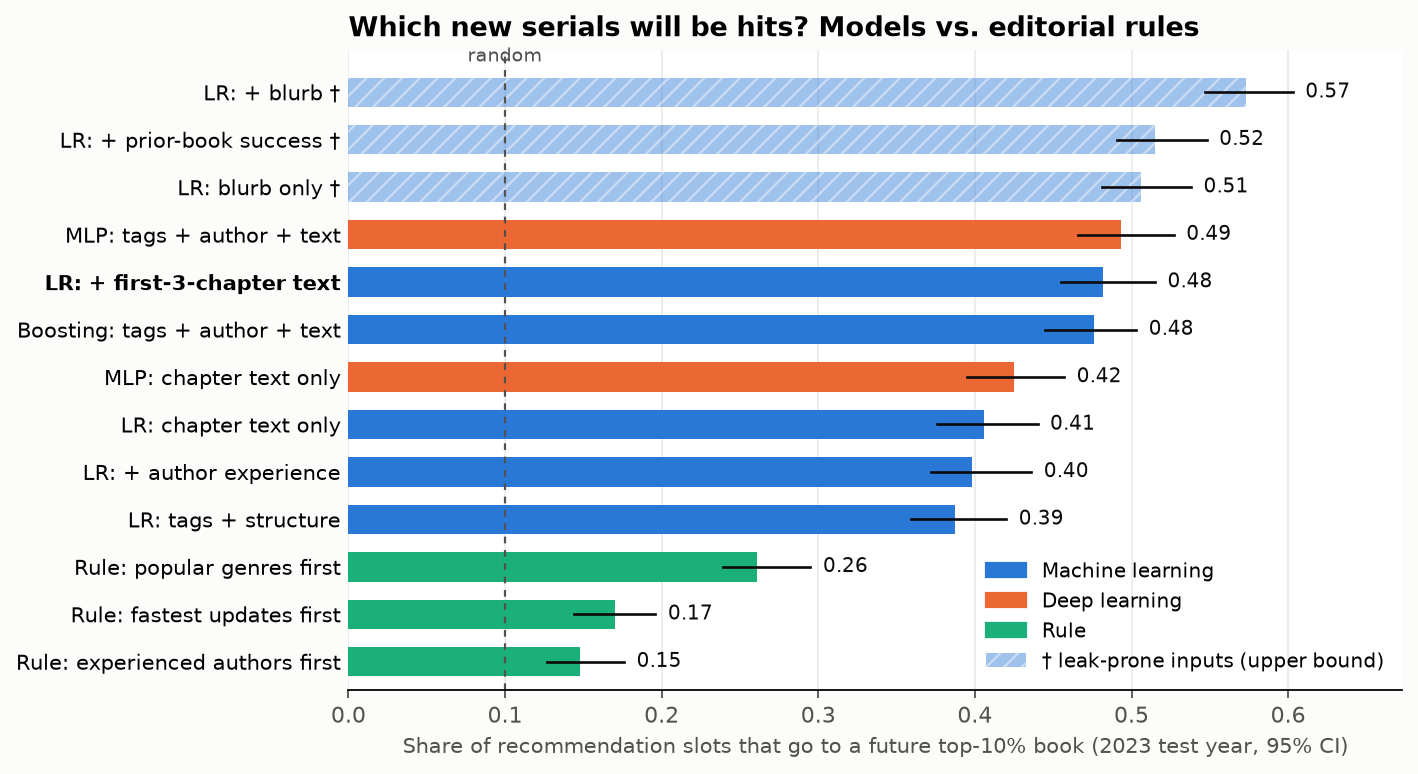

In [3]:
show("modeling/out/figs/model_comparison.png")

What each step adds (paired bootstrap, percentage points of Recall@slots):

In [4]:
pd.DataFrame({k: {"difference (pp)": v["diff"], "95% CI": f"{v['ci95'][0]:+.1f} to {v['ci95'][1]:+.1f}"} for k, v in r["increments_pp"].items()}).T

,difference (pp),95% CI
model vs best rule,22.1,+18.2 to +25.3
author experience,1.1,-0.2 to +3.0
chapter text,8.4,+4.8 to +11.2
boosting vs LR,-0.6,-3.8 to +1.8
MLP vs LR,1.1,-0.8 to +2.8
prior-book success (leak-prone),3.3,+1.5 to +5.5
blurb (leak-prone),5.8,+3.2 to +8.5


First-time authors: two thirds of new serials, with no track record to go on.

In [5]:
g = r["by_group"]
pd.DataFrame({name: {"serials": g[k]["n"], "future hits": g[k]["n_positive"],
                     "rule recall": g[k]["rule_hot_genre"]["recall_at_slots"], "S+A recall": g[k]["lr_SA"]["recall_at_slots"],
                     "main model recall": g[k]["lr_SAT"]["recall_at_slots"], "main model AUC": g[k]["lr_SAT"]["auc"]}
              for name, k in [("all", "all"), ("first-time authors", "first_time_author"), ("returning authors", "returning_author")]}).T

,serials,future hits,rule recall,S+A recall,main model recall,main model AUC
all,8075.0,811.0,0.261,0.398,0.482,0.887
first-time authors,5383.0,451.0,0.246,0.344,0.430,0.878
returning authors,2692.0,360.0,0.317,0.461,0.536,0.894


Takeaways: the model nearly doubles the rule (0.482 vs 0.261, +22.1 points, CI +18.2 to +25.3). Reading the chapters is the key step (+8.4); author experience adds little on top (+1.1, not significant). Gradient boosting and the MLP are not distinguishable from logistic regression, which also had the best 2022 validation AUC, so the simple model is the main one. First-time authors are harder but the gain holds (0.430 vs 0.246), and text adds about 9 points for them (0.344 → 0.430). Text alone already beats the rule (0.406), so the headline does not depend on tags that authors may edit later.